# Mini Project - Sales Prediction

## 1. - Data Analysis

In [214]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
import seaborn as sns

In [215]:
#df = pd.read_csv("./REAL_DATA - REAL_DATA.csv")
df = pd.read_csv("./sales - sales.csv")
df.head()

,Unnamed: 0,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
0,425390,366,4,2013-04-18,517,1,0,0,0,4422
1,291687,394,6,2015-04-11,694,1,0,0,0,8297
2,411278,807,4,2013-08-29,970,1,1,0,0,9729
3,664714,802,2,2013-05-28,473,1,1,0,0,6513
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882


In [216]:
df.shape

(640840, 10)

In [217]:
df.describe()

,Unnamed: 0,store_ID,day_of_week,nb_customers_on_day,open,promotion,school_holiday,sales
count,640840.000000,640840.000000,640840.000000,640840.000000,640840.000000,640840.000000,640840.000000,640840.000000
mean,355990.675084,558.211348,4.000189,633.398577,0.830185,0.381718,0.178472,5777.469011
std,205536.290268,321.878521,1.996478,464.094416,0.375470,0.485808,0.382910,3851.338083
min,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,178075.750000,280.000000,2.000000,405.000000,1.000000,0.000000,0.000000,3731.000000
50%,355948.500000,558.000000,4.000000,609.000000,1.000000,0.000000,0.000000,5746.000000
75%,533959.250000,837.000000,6.000000,838.000000,1.000000,1.000000,0.000000,7860.000000
max,712044.000000,1115.000000,7.000000,5458.000000,1.000000,1.000000,1.000000,41551.000000


In [218]:
#df.isnull().sum
df.isnull().mean()*100

Unnamed: 0             0.0
store_ID               0.0
day_of_week            0.0
date                   0.0
nb_customers_on_day    0.0
open                   0.0
promotion              0.0
state_holiday          0.0
school_holiday         0.0
sales                  0.0
dtype: float64

In [219]:
df.duplicated().sum()

np.int64(0)

In [220]:
df['sales'].describe()

count    640840.000000
mean       5777.469011
std        3851.338083
min           0.000000
25%        3731.000000
50%        5746.000000
75%        7860.000000
max       41551.000000
Name: sales, dtype: float64

In [221]:
store_counts = df.groupby(["store_ID"]).size()
store_counts
#store_counts.describe()

store_ID
1       610
2       600
3       593
4       581
5       592
       ... 
1111    590
1112    599
1113    593
1114    579
1115    592
Length: 1115, dtype: int64

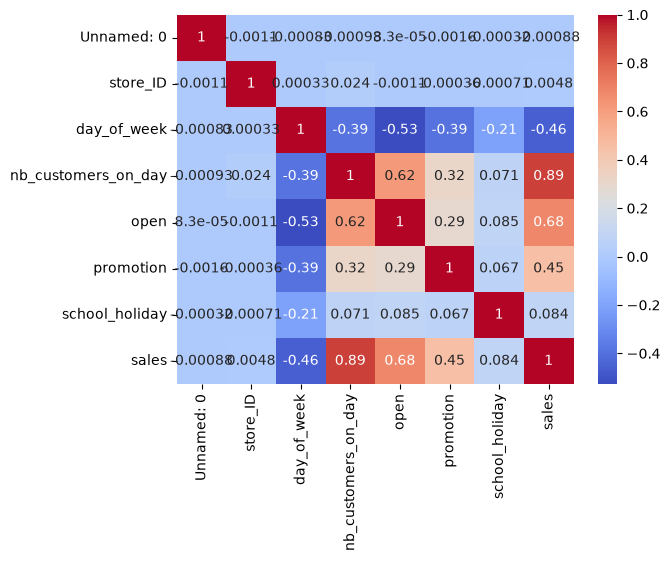

In [222]:
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.show()

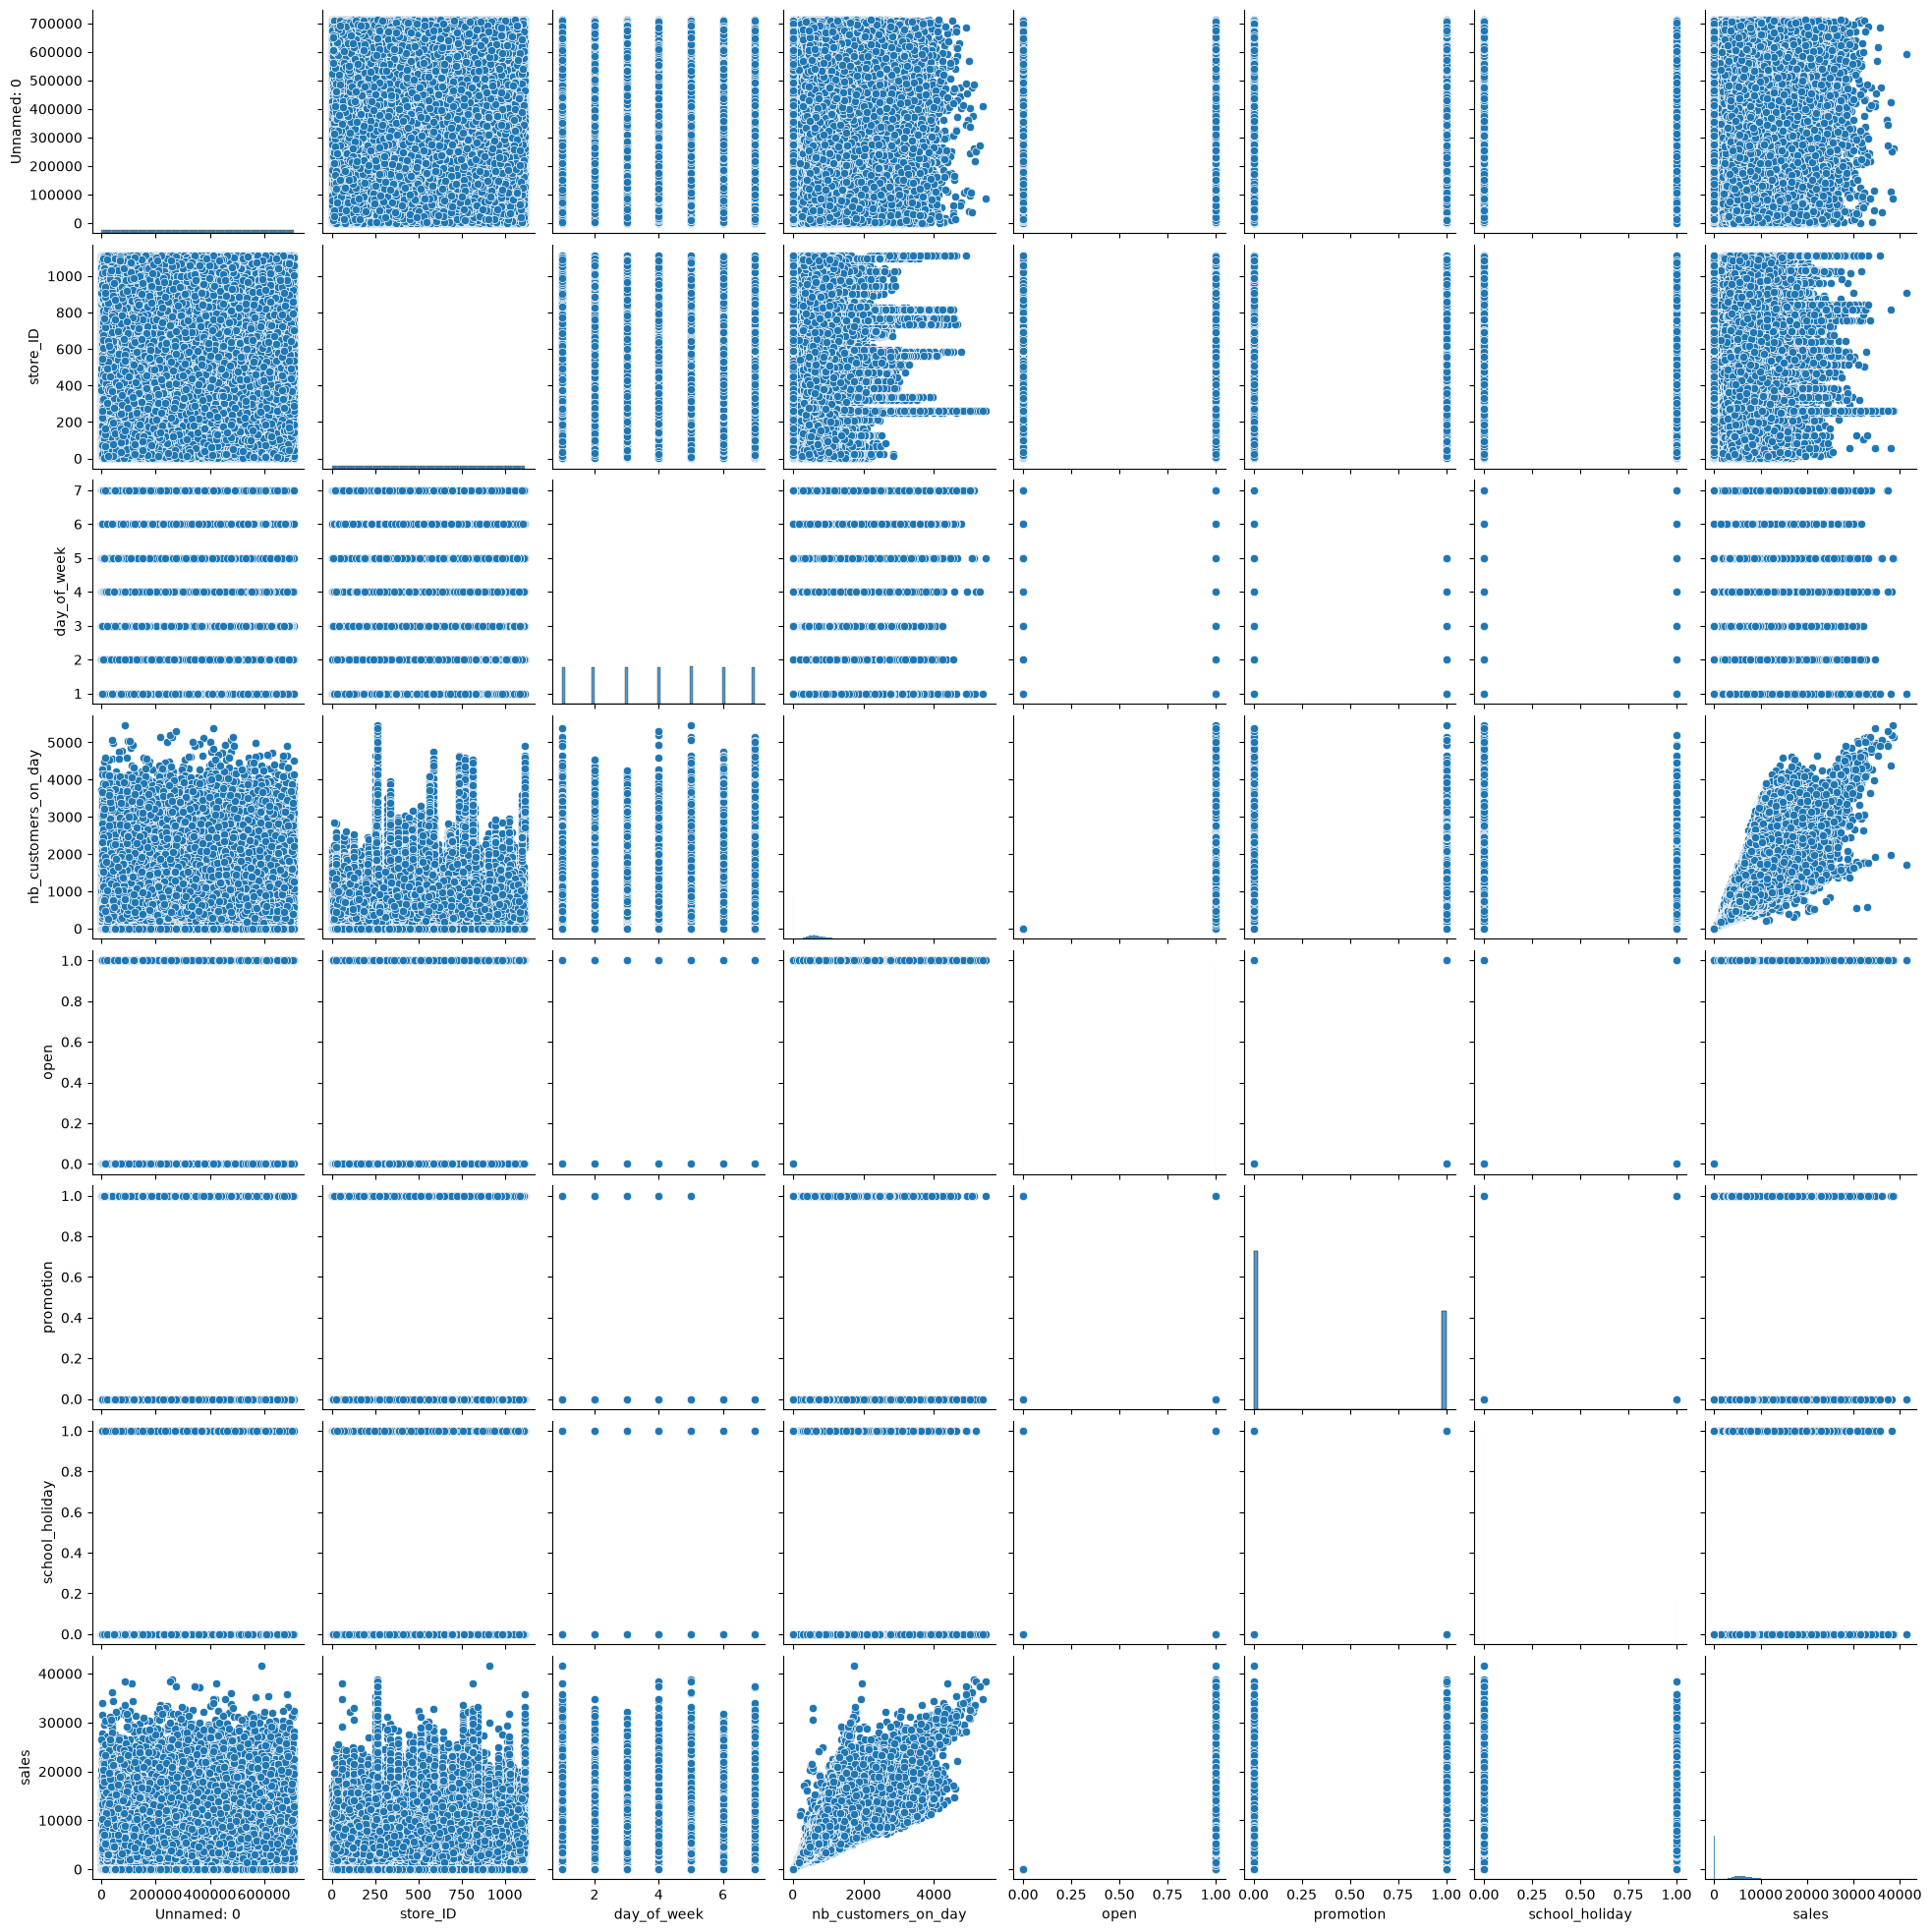

In [223]:
sns.pairplot(df)
plt.show()

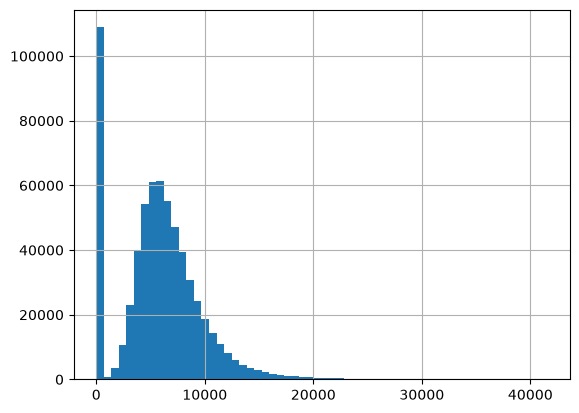

In [224]:
X = df.drop('sales', axis=1)
y = df['sales']
df['sales'].hist(bins = 60)
plt.show()

In [225]:
print("Sales mean = ", df['sales'].mean())
print("Sales median = ", df['sales'].median())
print("Sales skew = ", df['sales'].skew())

Sales mean =  5777.469010985581
Sales median =  5746.0
Sales skew =  0.6423662668092174


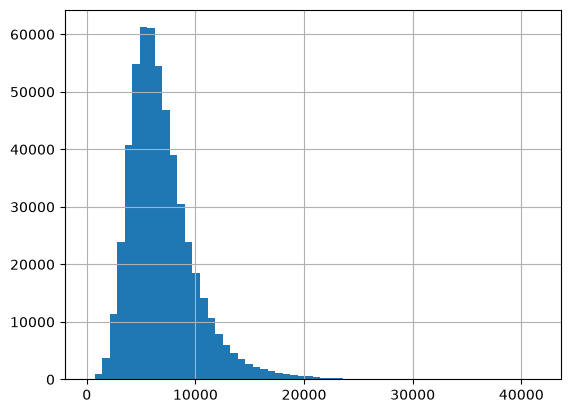

In [226]:
df1 = df[df['sales'] != 0]
df1['sales'].hist(bins = 60)
plt.show()

In [227]:
Q1 = df['sales'].quantile(0.25)
Q3 = df['sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[df['sales'] > upper_bound]

print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Q1: 3731.0
Q3: 7860.0
IQR: 4129.0
Lower Bound: -2462.5
Upper Bound: 14053.5
Number of outliers: 16821
Percentage: 2.6248361525497788


In [228]:
store_data = df.groupby("store_ID")[['sales']].sum()
print(store_data)
store_data2 = df.groupby("store_ID")['sales'].sum()
print(store_data2)

            sales
store_ID         
1         2418077
2         2493044
3         3443248
4         4624267
5         2283572
...           ...
1111      2607237
1112      4950139
1113      3288394
1114      9953850
1115      3058095

[1115 rows x 1 columns]
store_ID
1       2418077
2       2493044
3       3443248
4       4624267
5       2283572
         ...   
1111    2607237
1112    4950139
1113    3288394
1114    9953850
1115    3058095
Name: sales, Length: 1115, dtype: int64


In [229]:
store_stats = df.groupby('store_ID')['sales'].agg(
    Q1 = lambda x: x.quantile(0.25),
    Q3 = lambda x: x.quantile(0.75)
)
store_stats['IQR'] = store_stats['Q3'] - store_stats['Q1']
store_stats['lower_bound'] = store_stats['Q1'] - 1.5 * store_stats['IQR']
store_stats['upper_bound'] = store_stats['Q3'] + 1.5 * store_stats['IQR']
store_stats

,Q1,Q3,IQR,lower_bound,upper_bound
store_ID,,,,,
1,3583.00,5240.00,1657.00,1097.500,7725.500
2,2754.50,5744.25,2989.75,-1730.125,10228.875
3,4299.00,8158.00,3859.00,-1489.500,13946.500
4,7268.00,10275.00,3007.00,2757.500,14785.500
5,2151.75,5350.25,3198.50,-2646.000,10148.000
...,...,...,...,...,...
1111,3387.00,5947.50,2560.50,-453.750,9788.250
1112,6735.00,11027.50,4292.50,296.250,17466.250
1113,5155.00,7170.00,2015.00,2132.500,10192.500


In [230]:
df_analysis = df.merge(
    store_stats[['upper_bound']],
    on='store_ID',
    how='left'
)
outliers_by_store = df_analysis[df_analysis['sales'] > df_analysis['upper_bound']]
# print(outliers_by_store)
# print(outliers_by_store.size)
# outliers_by_store2 = outliers_by_store.groupby("store_ID")[["store_ID"]].mean()
# print(outliers_by_store2.size)
print(outliers_by_store.groupby("store_ID").size())
#print(outliers_by_store.groupby("store_ID").count())

print('outliers: ', len(outliers_by_store))
print('oulier percentage: ', len(outliers_by_store) / len(df) * 100)

outliers_by_store.groupby('store_ID').size().sort_values(
    ascending=False
).head(10)

store_ID
1        7
2        3
3        2
4       10
5        2
        ..
1111     6
1112    17
1113    12
1114    10
1115     5
Length: 1040, dtype: int64
outliers:  7379
oulier percentage:  1.1514574620810185


store_ID
274    71
262    59
85     46
68     30
248    29
676    26
811    25
896    24
118    23
504    23
dtype: int64

In [231]:
store_outlier_analysis = pd.DataFrame({
    'total_days': df.groupby('store_ID').size(),
    'outlier_days': outliers_by_store.groupby('store_ID').size()
}).fillna(0)

store_outlier_analysis['outlier_percentage'] = (
    store_outlier_analysis['outlier_days'] /
    store_outlier_analysis['total_days'] * 100
)

store_outlier_analysis.sort_values(
    'outlier_percentage',
    ascending=False
).head(10)

,total_days,outlier_days,outlier_percentage
store_ID,,,
274,582,71.0,12.199313
262,595,59.0,9.915966
85,613,46.0,7.504078
68,607,30.0,4.942339
248,607,29.0,4.777595
676,592,26.0,4.391892
58,472,20.0,4.237288
811,602,25.0,4.152824
896,601,24.0,3.993344


In [232]:
store_274 = df[df['store_ID'] == 274]

store_274['sales'].describe()

count     582.000000
mean     3985.828179
std      1399.147554
min         0.000000
25%      3155.000000
50%      3583.000000
75%      4281.000000
max      9466.000000
Name: sales, dtype: float64

In [233]:
store_274.groupby('open')['sales'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
open,,,,,
0,6,0.000000,0.0,0,0
1,576,4027.347222,3594.5,1653,9466


In [234]:
store_274.groupby('promotion')['sales'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
promotion,,,
0,342,4111.210526,3509.0
1,240,3807.158333,3674.0


In [235]:
outliers_by_store[
    outliers_by_store['store_ID'] == 274
].groupby('promotion')['sales'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
promotion,,,,,
0,61,6875.377049,6796.0,5989,9466
1,10,7442.300000,7450.0,6210,9017


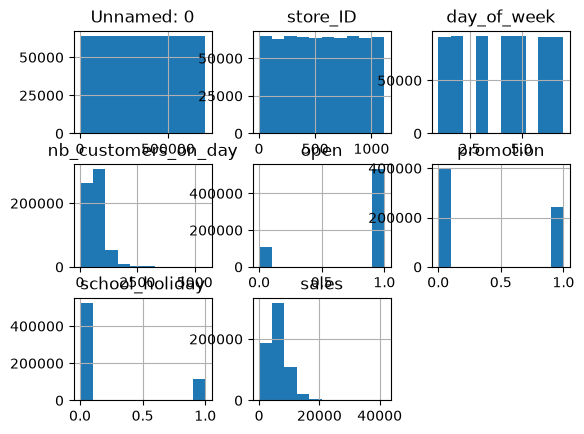

In [236]:
df.hist()
plt.show()

## 2. - Data Preprocessing

In [237]:
df.dtypes

Unnamed: 0             int64
store_ID               int64
day_of_week            int64
date                     str
nb_customers_on_day    int64
open                   int64
promotion              int64
state_holiday            str
school_holiday         int64
sales                  int64
dtype: object

In [238]:
df.head(5)

,Unnamed: 0,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
0,425390,366,4,2013-04-18,517,1,0,0,0,4422
1,291687,394,6,2015-04-11,694,1,0,0,0,8297
2,411278,807,4,2013-08-29,970,1,1,0,0,9729
3,664714,802,2,2013-05-28,473,1,1,0,0,6513
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882


In [239]:
df['date'] = pd.to_datetime(df['date'])
df.dtypes

Unnamed: 0                      int64
store_ID                        int64
day_of_week                     int64
date                   datetime64[us]
nb_customers_on_day             int64
open                            int64
promotion                       int64
state_holiday                     str
school_holiday                  int64
sales                           int64
dtype: object

In [240]:
df.dtypes

Unnamed: 0                      int64
store_ID                        int64
day_of_week                     int64
date                   datetime64[us]
nb_customers_on_day             int64
open                            int64
promotion                       int64
state_holiday                     str
school_holiday                  int64
sales                           int64
dtype: object

In [241]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df.head(5)

,Unnamed: 0,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales,year,month,day
0,425390,366,4,2013-04-18,517,1,0,0,0,4422,2013,4,18
1,291687,394,6,2015-04-11,694,1,0,0,0,8297,2015,4,11
2,411278,807,4,2013-08-29,970,1,1,0,0,9729,2013,8,29
3,664714,802,2,2013-05-28,473,1,1,0,0,6513,2013,5,28
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882,2013,10,10


In [242]:
df.groupby('day_of_week')['sales'].agg(
    ['count','mean','median']
)

,count,mean,median
day_of_week,,,
1,90971,7812.766948,7311.0
2,91686,7004.780054,6467.0
3,91651,6555.350536,6134.0
4,91972,6255.380268,6025.5
5,92138,6726.462697,6439.0
6,91347,5850.032820,5410.0
7,91075,210.680439,0.0


In [243]:
df.groupby(['day_of_week', 'open'])[['sales']].agg(
    ['count','mean','median']
)

sales                     
                  count         mean  median
day_of_week open                            
1           0      4516     0.000000     0.0
            1     86455  8220.868914  7540.0
2           0      1089     0.000000     0.0
            1     90597  7088.979370  6505.0
3           0      2370     0.000000     0.0
            1     89281  6729.364949  6213.0
4           0      7083     0.000000     0.0
            1     84889  6777.319017  6250.0
5           0      4560     0.000000     0.0
            1     87578  7076.695289  6584.0
6           0       444     0.000000     0.0
            1     90903  5878.606295  5425.0
7           0     88762     0.000000     0.0
            1      2313  8295.599222  6965.0

### 2 - 1 : Feature's preparation

|     column            | feature type |    decision                    |
|-----------------------|--------------|--------------------------------|
| stroe_ID              | Categorical  | One-Hot Encoding               |
| day_of_week           | Categorical  | One-Hot Encoding               |
| date                  | Datetime     | convert to year, month and day |
| nb_customers_on_day.  | Numerical    | Should be used in prediction?  |
| open                  | Binary       | Keep it                        |
| promotion             | Binary       | Keep it                        |
| state_holiday         | Categorial   | One-Hot Encoding               |
| school_holiday        | Binary       | Keep it                        |
| sales                 | Target       | Target variable                |
| Unnamed               | Numerical    | delete it                      |

In [244]:
df['state_holiday'].value_counts()

state_holiday
0    621160
a     12842
b      4214
c      2624
Name: count, dtype: int64

In [245]:
df['state_holiday'].unique()

<StringArray>
['0', 'a', 'c', 'b']
Length: 4, dtype: str

In [246]:
holiday_encoded = pd.get_dummies(
    df['state_holiday'],
    prefix='state_holiday',
    dtype=int
)

In [247]:
df.head(10)

,Unnamed: 0,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales,year,month,day
0,425390,366,4,2013-04-18,517,1,0,0,0,4422,2013,4,18
1,291687,394,6,2015-04-11,694,1,0,0,0,8297,2015,4,11
2,411278,807,4,2013-08-29,970,1,1,0,0,9729,2013,8,29
3,664714,802,2,2013-05-28,473,1,1,0,0,6513,2013,5,28
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882,2013,10,10
5,687329,674,2,2013-03-19,1016,1,1,0,0,8406,2013,3,19
6,600327,659,7,2014-06-08,0,0,0,0,0,0,2014,6,8
7,96265,27,3,2014-07-16,1106,1,1,0,1,11162,2014,7,16
8,364435,347,6,2013-05-11,448,1,0,0,0,5559,2013,5,11
9,163146,288,2,2013-06-25,291,1,0,0,0,3997,2013,6,25


In [248]:
holiday_encoded.head(10)

,state_holiday_0,state_holiday_a,state_holiday_b,state_holiday_c
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,1,0,0,0
5,1,0,0,0
6,1,0,0,0
7,1,0,0,0
8,1,0,0,0
9,1,0,0,0


In [249]:
holiday_encoded = pd.get_dummies(
    df['state_holiday'],
    prefix='state_holiday',
    drop_first=True,
    dtype=int
)

In [250]:
holiday_encoded.head(10)

,state_holiday_a,state_holiday_b,state_holiday_c
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
5,0,0,0
6,0,0,0
7,0,0,0
8,0,0,0
9,0,0,0


In [251]:
holiday_encoded.sum()

state_holiday_a    12842
state_holiday_b     4214
state_holiday_c     2624
dtype: int64

In [252]:
df = pd.concat(
    [df, holiday_encoded],
    axis=1
)

In [ ]:
df = df.drop(columns=['state_holiday'])
'state_holiday' in df.columns
df

In [257]:
df.head(10)
df.dtypes

Unnamed: 0                      int64
store_ID                        int64
day_of_week                     int64
date                   datetime64[us]
nb_customers_on_day             int64
open                            int64
promotion                       int64
school_holiday                  int64
sales                           int64
year                            int32
month                           int32
day                             int32
state_holiday_a                 int64
state_holiday_b                 int64
state_holiday_c                 int64
dtype: object

In [260]:
df['store_ID'].unique()

array([366, 394, 807, ..., 450,  38, 989], shape=(1115,))

In [259]:
df['day_of_week'].unique()

array([4, 6, 2, 7, 3, 5, 1])

In [261]:
day_of_week_encoded = pd.get_dummies(
    df['day_of_week'],
    prefix='day',
    drop_first=True,
    dtype=int
)

In [263]:
day_of_week_encoded.head(10)

,day_2,day_3,day_4,day_5,day_6,day_7
0,0,0,1,0,0,0
1,0,0,0,0,1,0
2,0,0,1,0,0,0
3,1,0,0,0,0,0
4,0,0,1,0,0,0
5,1,0,0,0,0,0
6,0,0,0,0,0,1
7,0,1,0,0,0,0
8,0,0,0,0,1,0
9,1,0,0,0,0,0


In [264]:
day_of_week_encoded.shape

(640840, 6)

In [265]:
df = pd.concat([df, day_of_week_encoded], axis=1)

In [ ]:
df = df.drop(columns=['day_of_week'])


In [268]:
df.dtypes

Unnamed: 0                      int64
store_ID                        int64
date                   datetime64[us]
nb_customers_on_day             int64
open                            int64
promotion                       int64
school_holiday                  int64
sales                           int64
year                            int32
month                           int32
day                             int32
state_holiday_a                 int64
state_holiday_b                 int64
state_holiday_c                 int64
day_2                           int64
day_3                           int64
day_4                           int64
day_5                           int64
day_6                           int64
day_7                           int64
dtype: object

### 2.2 – Dropping / Keeping Selected Features

Based on the decisions to keep or drop `nb_customers_on_day` and to drop, keep, or apply One-Hot Encoding to `store_ID`, we will evaluate six different modeling scenarios.

| Version | `store_ID` | `nb_customers_on_day` | Description |
|---|---|---|---|
| A1 | Drop | Drop | The model will not use either `store_ID` or `nb_customers_on_day` as input features. |
| B1 | Keep (Numerical) | Drop | Keep `store_ID` in its original numerical format. |
| C1 | One-Hot Encoding | Drop | Apply One-Hot Encoding to `store_ID`. |
| A2 | Drop | Keep | Use `nb_customers_on_day` as an input feature, but exclude `store_ID`. |
| B2 | Keep (Numerical) | Keep | Use both `store_ID` and `nb_customers_on_day` as input features. |
| C2 | One-Hot Encoding | Keep | Apply One-Hot Encoding to `store_ID` and use `nb_customers_on_day` as an input feature. |

I will start with **Version A1** as the baseline model.

## A1 model

In [269]:
X = df.drop(columns=[
    'sales',
    'store_ID',
    'nb_customers_on_day',
    'date',
    'Unnamed: 0'
])

y = df['sales']

In [274]:
X.head(10)


,open,promotion,school_holiday,year,month,day,state_holiday_a,state_holiday_b,state_holiday_c,day_2,day_3,day_4,day_5,day_6,day_7
0,1,0,0,2013,4,18,0,0,0,0,0,1,0,0,0
1,1,0,0,2015,4,11,0,0,0,0,0,0,0,1,0
2,1,1,0,2013,8,29,0,0,0,0,0,1,0,0,0
3,1,1,0,2013,5,28,0,0,0,1,0,0,0,0,0
4,1,1,0,2013,10,10,0,0,0,0,0,1,0,0,0
5,1,1,0,2013,3,19,0,0,0,1,0,0,0,0,0
6,0,0,0,2014,6,8,0,0,0,0,0,0,0,0,1
7,1,1,1,2014,7,16,0,0,0,0,1,0,0,0,0
8,1,0,0,2013,5,11,0,0,0,0,0,0,0,1,0
9,1,0,0,2013,6,25,0,0,0,1,0,0,0,0,0


In [275]:
print(X.shape)
print(y.shape)
print(X.columns.tolist())

(640840, 15)
(640840,)
['open', 'promotion', 'school_holiday', 'year', 'month', 'day', 'state_holiday_a', 'state_holiday_b', 'state_holiday_c', 'day_2', 'day_3', 'day_4', 'day_5', 'day_6', 'day_7']


In [276]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [278]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (512672, 15)
X_val: (128168, 15)
y_train: (512672,)
y_val: (128168,)


## 3. - Model, Training, Prediction & Metrices

## A1 model

In [279]:
from sklearn.linear_model import LinearRegression

model_A1 = LinearRegression()

model_A1.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ 7868.16, 2216.06, 192.62,...,-1083.98,-1046.68, 940.71]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['open','promotion','school_holiday',...,'day_5','day_6','day_7']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.339e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)


In [280]:
coefficients = pd.DataFrame({
    'Feature': model_A1.feature_names_in_,
    'Coefficient': model_A1.coef_
})

coefficients['Abs_Coefficient'] = (
    coefficients['Coefficient'].abs()
)

coefficients.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

,Feature,Coefficient,Abs_Coefficient
0,open,7868.160763,7868.160763
1,promotion,2216.057043,2216.057043
8,state_holiday_c,1798.526072,1798.526072
10,day_3,-1436.411866,1436.411866
11,day_4,-1386.539239,1386.539239
6,state_holiday_a,1140.746572,1140.746572
12,day_5,-1083.977313,1083.977313
9,day_2,-1071.418227,1071.418227
13,day_6,-1046.675021,1046.675021
14,day_7,940.709624,940.709624


In [281]:
y_pred = model_A1.predict(X_val)

In [282]:
print(y_pred[:10])

[8015.42666044   42.72079815 8300.59312685 8015.42666044 5713.37100653
 5828.64255892 8022.8661226  5178.1564353  7926.94727712 5493.68291012]


In [283]:
comparison = pd.DataFrame({
    'Actual': y_val.iloc[:10].values,
    'Predicted': y_pred[:10]
})

comparison['Error'] = (
    comparison['Actual'] - comparison['Predicted']
)

comparison

,Actual,Predicted,Error
0,10108,8015.426660,2092.573340
1,0,42.720798,-42.720798
2,4232,8300.593127,-4068.593127
3,5189,8015.426660,-2826.426660
4,5318,5713.371007,-395.371007
5,3266,5828.642559,-2562.642559
6,7229,8022.866123,-793.866123
7,4164,5178.156435,-1014.156435
8,5948,7926.947277,-1978.947277
9,7326,5493.682910,1832.317090


In [284]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_val, y_pred)

print("MAE:", mae)

MAE: 1748.725789720474


In [285]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_val, y_pred)

rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 6658412.199755426
RMSE: 2580.3899317264872


In [286]:
from sklearn.metrics import r2_score

r2 = r2_score(y_val, y_pred)

print("R2:", r2)

R2: 0.5495491302963846


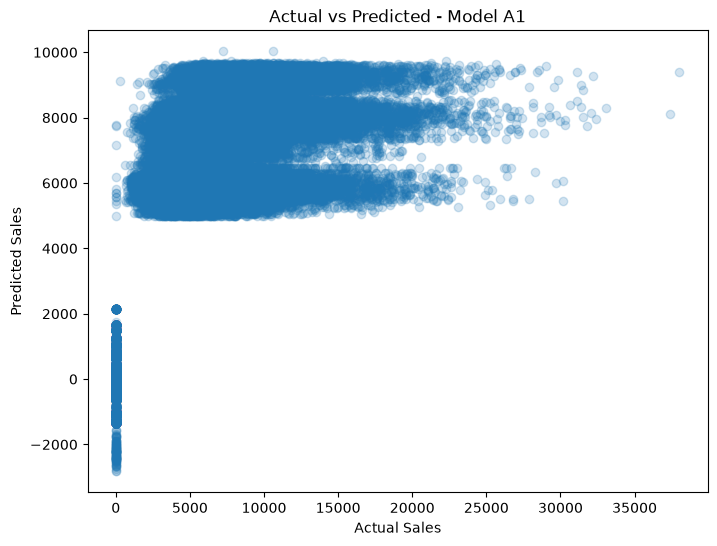

In [287]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred, alpha=0.2)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted - Model A1')

plt.show()

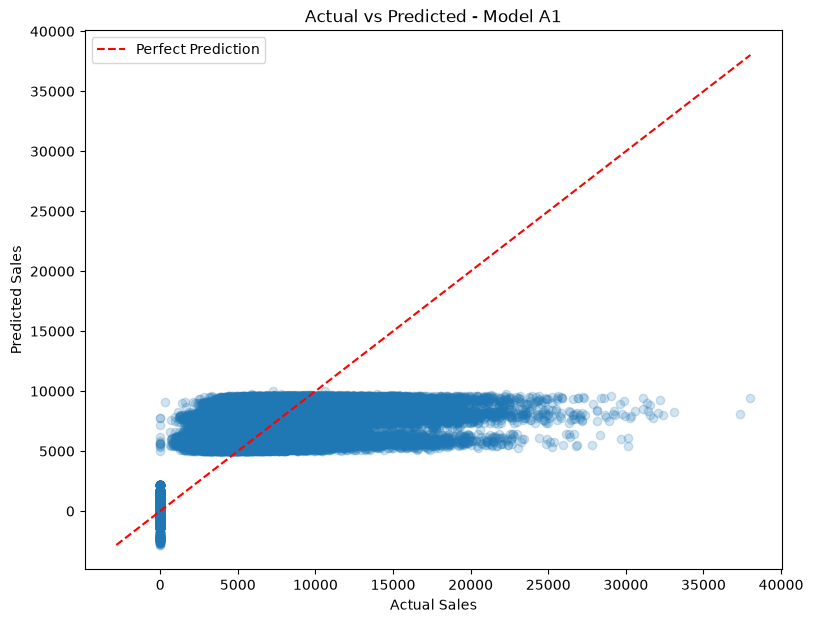

In [288]:
plt.figure(figsize=(9, 7))

plt.scatter(y_val, y_pred, alpha=0.2)

min_val = min(y_val.min(), y_pred.min())
max_val = max(y_val.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted - Model A1')
plt.legend()
plt.show()

## B1 model

In [291]:
X_B1 = df.drop(columns=[
    'sales',
    'nb_customers_on_day',
    'date',
    'Unnamed: 0'
])

y_B1 = df['sales']

In [292]:
print(X_B1.shape)
print(y_B1.shape)

(640840, 16)
(640840,)


In [293]:
X_train_B1, X_val_B1, y_train_B1, y_val_B1 = train_test_split(
    X_B1,
    y_B1,
    test_size=0.2,
    random_state=42
)

In [294]:
model_B1 = LinearRegression()

model_B1.fit(X_train_B1, y_train_B1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ 0.06, 7867.87, 2215.99,...,-1083.94,-1046.65, 940.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['store_ID','open','promotion',...,'day_5','day_6','day_7']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.34e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [295]:
y_pred_B1 = model_B1.predict(X_val_B1)

mae_B1 = mean_absolute_error(y_val_B1, y_pred_B1)
rmse_B1 = np.sqrt(mean_squared_error(y_val_B1, y_pred_B1))
r2_B1 = r2_score(y_val_B1, y_pred_B1)

print("MAE:", mae_B1)
print("RMSE:", rmse_B1)
print("R2:", r2_B1)

MAE: 1748.891505522594
RMSE: 2580.298859016386
R2: 0.5495809263106357


## C1 model

In [296]:
X_C1 = df.drop(columns=[
    'sales',
    'nb_customers_on_day',
    'date',
    'Unnamed: 0'
])

y_C1 = df['sales']

In [297]:
print(X_C1.shape)
print(y_C1.shape)

(640840, 16)
(640840,)


In [298]:
X_train_C1, X_val_C1, y_train_C1, y_val_C1 = train_test_split(
    X_C1,
    y_C1,
    test_size=0.2,
    random_state=42
)

In [299]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore'
)

In [300]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('store', encoder, ['store_ID'])
    ],
    remainder='passthrough'
)

In [301]:
from sklearn.pipeline import Pipeline

model_C1 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [302]:
model_C1.fit(X_train_C1, y_train_C1)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['store_ID','open','promotion',...,'day_5','day_6','day_7']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('store', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with

In [303]:
y_pred_C1 = model_C1.predict(X_val_C1)

In [304]:
print(y_pred_C1.shape)
print(y_pred_C1[:10])
print(y_val_C1[:10].values)

(128168,)
[8139.14354028  214.53498119 5898.6314654  7233.88234051 5463.7540806
 2710.15084748 7271.02820729 4875.8371349  6673.21842438 5353.55992266]
[10108     0  4232  5189  5318  3266  7229  4164  5948  7326]


In [305]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_C1 = mean_absolute_error(y_val_C1, y_pred_C1)

mse_C1 = mean_squared_error(y_val_C1, y_pred_C1)

rmse_C1 = np.sqrt(mse_C1)

r2_C1 = r2_score(y_val_C1, y_pred_C1)

print(f"MAE:  {mae_C1:.2f}")
print(f"RMSE: {rmse_C1:.2f}")
print(f"R²:   {r2_C1:.4f}")

MAE:  1149.22
RMSE: 1617.91
R²:   0.8229


In [306]:
results = pd.DataFrame([
    {'Model': 'A1', 'MAE': mae, 'RMSE': rmse, 'R2': r2},
    {'Model': 'B1', 'MAE': mae_B1, 'RMSE': rmse_B1, 'R2': r2_B1},
    {'Model': 'C1', 'MAE': mae_C1, 'RMSE': rmse_C1, 'R2': r2_C1}
])

results

,Model,MAE,RMSE,R2
0,A1,1748.725790,2580.389932,0.549549
1,B1,1748.891506,2580.298859,0.549581
2,C1,1149.223419,1617.912980,0.822913


## A2 model

In [307]:
X_A2 = df.drop(columns=[
    'sales',
    'store_ID',
    'date',
    'Unnamed: 0'
])

y_A2 = df['sales']

In [308]:
print(X_A2.shape)
print(y_A2.shape)

(640840, 16)
(640840,)


In [309]:
X_train_A2, X_val_A2, y_train_A2, y_val_A2 = train_test_split(
    X_A2,
    y_A2,
    test_size=0.2,
    random_state=42
)

In [310]:
print(X_train_A2.shape)
print(X_val_A2.shape)
print(y_train_A2.shape)
print(y_val_A2.shape)

(512672, 16)
(128168, 16)
(512672,)
(128168,)


In [311]:
model_A2 = LinearRegression()

model_A2.fit(X_train_A2, y_train_A2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ 6.05, 509.88, 1412.5 ,..., -661.67, -348.42,-1739.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['nb_customers_on_day','open','promotion',...,'day_5','day_6','day_7']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.883e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [312]:
y_pred_A2 = model_A2.predict(X_val_A2)

In [313]:
print(y_pred_A2.shape)

(128168,)


In [314]:
mae_A2 = mean_absolute_error(y_val_A2, y_pred_A2)

mse_A2 = mean_squared_error(y_val_A2, y_pred_A2)

rmse_A2 = np.sqrt(mse_A2)

r2_A2 = r2_score(y_val_A2, y_pred_A2)

print(f"MAE:  {mae_A2:.2f}")
print(f"RMSE: {rmse_A2:.2f}")
print(f"R²:   {r2_A2:.4f}")

MAE:  976.74
RMSE: 1458.20
R²:   0.8561


## B2 model

In [315]:
X_B2 = df.drop(columns=[
    'sales',
    'date',
    'Unnamed: 0'
])

y_B2 = df['sales']

In [316]:
print(X_B2.shape)
print(y_B2.shape)

(640840, 17)
(640840,)


In [317]:
X_train_B2, X_val_B2, y_train_B2, y_val_B2 = train_test_split(
    X_B2,
    y_B2,
    test_size=0.2,
    random_state=42
)

In [318]:
print(X_train_B2.shape)
print(X_val_B2.shape)
print(y_train_B2.shape)
print(y_val_B2.shape)

(512672, 17)
(128168, 17)
(512672,)
(128168,)


In [319]:
model_B2 = LinearRegression()

model_B2.fit(X_train_B2, y_train_B2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](17,)","[ -0.14, 6.06, 505.56,..., -661.47, -348.01,-1740.98]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](17,)","['store_ID','nb_customers_on_day','open',...,'day_5','day_6','day_7']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.882e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(17)


In [320]:
y_pred_B2 = model_B2.predict(X_val_B2)

In [321]:
print(y_pred_B2.shape)

(128168,)


In [322]:
mae_B2 = mean_absolute_error(y_val_B2, y_pred_B2)

mse_B2 = mean_squared_error(y_val_B2, y_pred_B2)

rmse_B2 = np.sqrt(mse_B2)

r2_B2 = r2_score(y_val_B2, y_pred_B2)

print(f"MAE:  {mae_B2:.2f}")
print(f"RMSE: {rmse_B2:.2f}")
print(f"R²:   {r2_B2:.4f}")

MAE:  977.07
RMSE: 1457.41
R²:   0.8563


## C2 model

In [323]:
X_C2 = df.drop(columns=[
    'sales',
    'date',
    'Unnamed: 0'
])

y_C2 = df['sales']

In [324]:
print(X_C2.shape)
print(y_C2.shape)

(640840, 17)
(640840,)


In [325]:
X_train_C2, X_val_C2, y_train_C2, y_val_C2 = train_test_split(
    X_C2,
    y_C2,
    test_size=0.2,
    random_state=42
)

In [326]:
print(X_train_C2.shape)
print(X_val_C2.shape)
print(y_train_C2.shape)
print(y_val_C2.shape)

(512672, 17)
(128168, 17)
(512672,)
(128168,)


In [327]:
model_C2 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [328]:
model_C2.fit(X_train_C2, y_train_C2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['store_ID','nb_customers_on_day','open',...,'day_5','day_6','day_7']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('store', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concate

In [329]:
y_pred_C2 = model_C2.predict(X_val_C2)

print(y_pred_C2.shape)

(128168,)


In [330]:
mae_C2 = mean_absolute_error(y_val_C2, y_pred_C2)

mse_C2 = mean_squared_error(y_val_C2, y_pred_C2)

rmse_C2 = np.sqrt(mse_C2)

r2_C2 = r2_score(y_val_C2, y_pred_C2)

print(f"MAE:  {mae_C2:.2f}")
print(f"RMSE: {rmse_C2:.2f}")
print(f"R²:   {r2_C2:.4f}")

MAE:  560.78
RMSE: 808.19
R²:   0.9558


## 4. - Benchmark

In [331]:
results = pd.DataFrame([
    {'Model': 'A1', 'MAE': mae, 'RMSE': rmse, 'R2': r2},
    {'Model': 'B1', 'MAE': mae_B1, 'RMSE': rmse_B1, 'R2': r2_B1},
    {'Model': 'C1', 'MAE': mae_C1, 'RMSE': rmse_C1, 'R2': r2_C1},
    {'Model': 'A2', 'MAE': mae_A2, 'RMSE': rmse_A2, 'R2': r2_A2},
    {'Model': 'B2', 'MAE': mae_B2, 'RMSE': rmse_B2, 'R2': r2_B2},
    {'Model': 'C2', 'MAE': mae_C2, 'RMSE': rmse_C2, 'R2': r2_C2}
])

results.sort_values('R2', ascending=False)

,Model,MAE,RMSE,R2
5,C2,560.776960,808.188849,0.955812
4,B2,977.071506,1457.407932,0.856306
3,A2,976.743006,1458.198597,0.856150
2,C1,1149.223419,1617.912980,0.822913
1,B1,1748.891506,2580.298859,0.549581
0,A1,1748.725790,2580.389932,0.549549


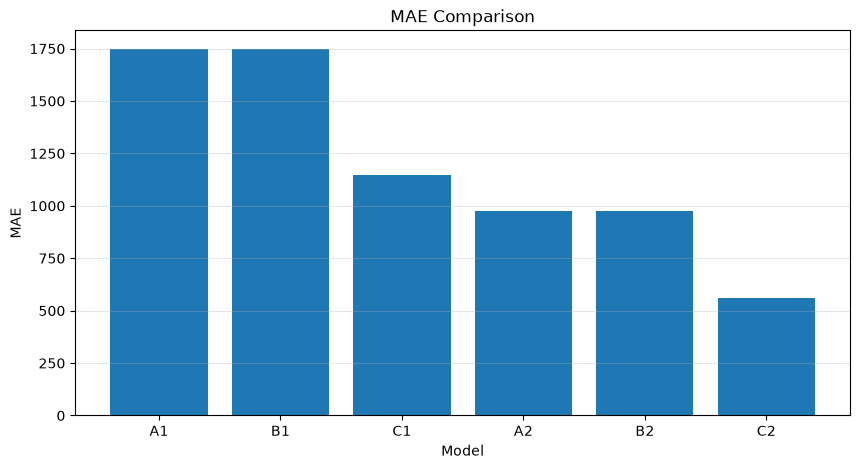

In [332]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(results['Model'], results['MAE'])

plt.title('MAE Comparison')
plt.xlabel('Model')
plt.ylabel('MAE')
plt.grid(axis='y', alpha=0.3)

plt.show()

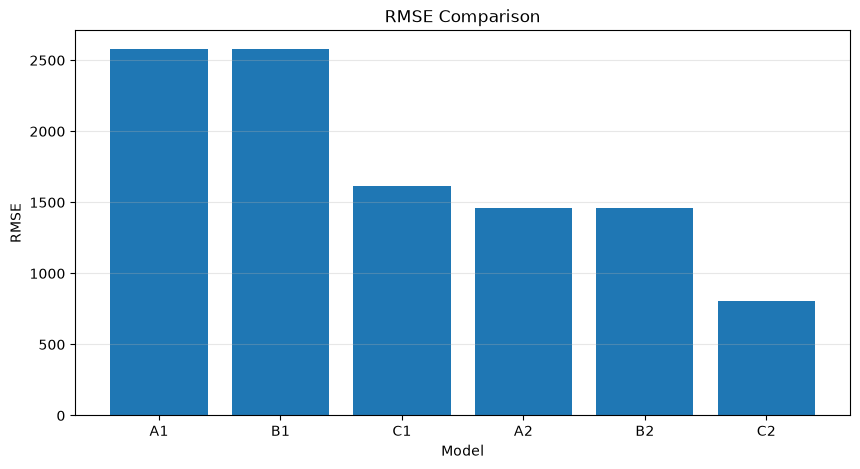

In [333]:
plt.figure(figsize=(10, 5))

plt.bar(results['Model'], results['RMSE'])

plt.title('RMSE Comparison')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.grid(axis='y', alpha=0.3)

plt.show()

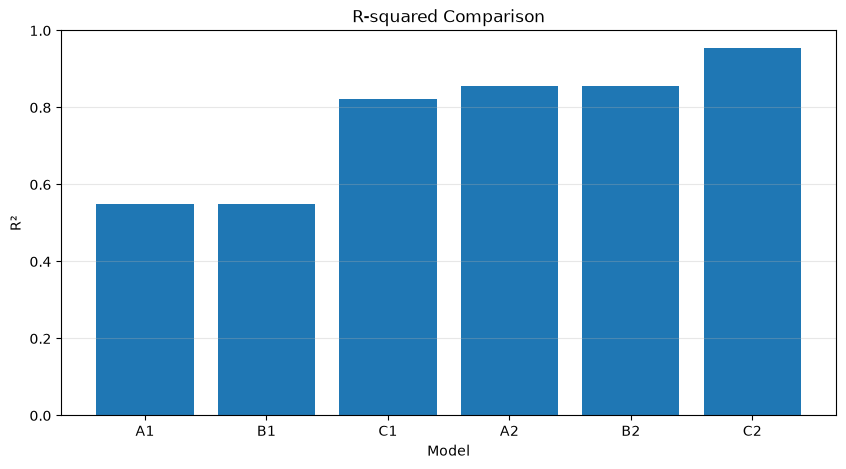

In [334]:
plt.figure(figsize=(10, 5))

plt.bar(results['Model'], results['R2'])

plt.title('R-squared Comparison')
plt.xlabel('Model')
plt.ylabel('R²')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

plt.show()

### 4.1 - Residual Analysis

In [335]:
residuals_C1 = y_val_C1 - y_pred_C1

residuals_C2 = y_val_C2 - y_pred_C2

In [336]:
print("C1 Residuals:")
print(residuals_C1.describe())

print("\nC2 Residuals:")
print(residuals_C2.describe())

C1 Residuals:
count    128168.000000
mean         -0.562513
std        1617.919194
min      -13357.256890
25%        -932.724314
50%        -130.288687
75%         787.291196
max       22710.294754
Name: sales, dtype: float64

C2 Residuals:
count    128168.000000
mean         -2.568669
std         808.187920
min       -7415.870560
25%        -447.457337
50%         -57.714038
75%         357.180869
max       23658.961689
Name: sales, dtype: float64


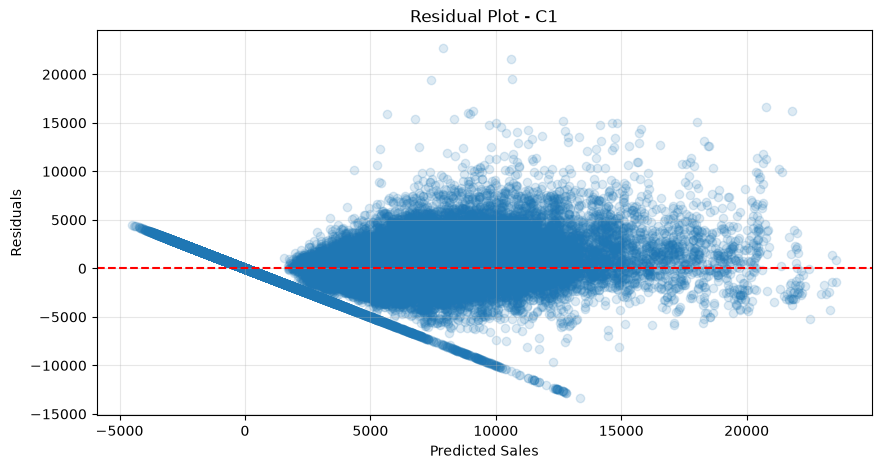

In [337]:
plt.figure(figsize=(10, 5))

plt.scatter(y_pred_C1, residuals_C1, alpha=0.15)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residual Plot - C1')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')

plt.grid(alpha=0.3)
plt.show()

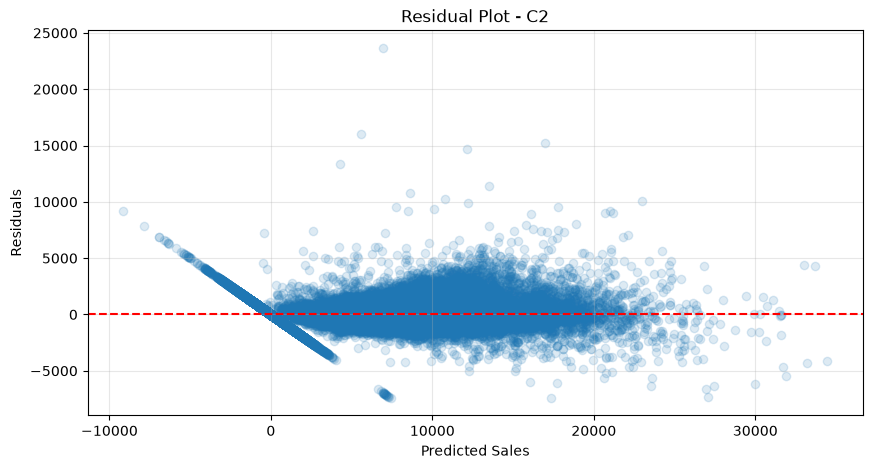

In [338]:
plt.figure(figsize=(10, 5))

plt.scatter(y_pred_C2, residuals_C2, alpha=0.15)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residual Plot - C2')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')

plt.grid(alpha=0.3)
plt.show()